### (2) 데이터 소개

#### 1) 기본 데이터

* 학습 데이터
    * air_2021.csv : 2021년 미세먼지 데이터
    * weather_2021.csv : 2021년 날씨 데이터
* 테스트 데이터
    * air_2022.csv : 2022년 미세먼지 데이터
    * weather_2022.csv : 2022년 날씨 데이터

#### 2) 데이터셋의 변수 소개(weather_2021)

* 증기압: 증기가 고체 또는 액체와 동적 평형 상태에 있을 때 증기의 압력 (증기가 되려는 힘)
* 이슬점 온도: 불포화 상태의 공기가 냉각될 때, 포화 상태에 도달하여 수증기의 응결이 시작되는 온도
* 일조: 일정한 물체나 땅의 겉면에 태양 광선이 비치는 시간 (1시간 중 비율)
* 일사(량): 태양으로부터 오는 태양 복사 에너지가 지표에 닿는 양 (면적당 에너지 량)
* 전운량: 하늘을 육안으로 관측하여 전부 구름일 때 10, 구름이 덮고 있는 하늘의 비율에 따라 0~10
* 중하층운량: 중층과 하층에 있는 구름의 분포량(중하층 구름이 날씨에 영향 주므로 따로 표기)
* 운형(운형약어): 구름의 종류. 약어 코드로 기재됨
* 최저운고: 가장 낮은 구름의 높이
* 현상번호(국내식): 비, 소낙비, 싸락눈, 눈보라 등의 기상현상을 나타낸 코드번호
* 지면온도: 지면 0cm 온도
* 지중온도: 땅 속 온도변수1


In [105]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [106]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

# 필요한 라이브러리

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.ensemble import GradientBoostingRegressor as GBR
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall

import joblib

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [108]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

## 필요한 함수

In [109]:
def vif(dataframe, features):
    """
    다중공선성(VIF)을 계산하는 함수 (const 자동 제거)

    Parameters:
    - dataframe: pd.DataFrame
        입력 데이터프레임
    - features: list of str
        독립 변수(컬럼명) 리스트

    Returns:
    - vif_df: pd.DataFrame
        독립 변수들과 해당하는 VIF 값을 담은 데이터프레임
        (const는 포함되지 않음)
    """
    X = dataframe[features]
    X_const = add_constant(X)

    vif_data = pd.DataFrame()
    vif_data["변수"] = X_const.columns
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    # const 행 제거
    vif_data = vif_data[vif_data["변수"] != "const"]

    return vif_data


In [110]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import warnings

def stepwise_feature_selection(X_train, y_train, variables=None, sl_enter=0.05, sl_remove=0.05):
    """
    전진 선택 + 후진 제거를 통한 변수 선택

    Parameters:
    - X_train: pd.DataFrame
    - y_train: pd.Series 또는 np.array
    - variables: 선택에 사용할 변수 리스트 (기본: X_train.columns)
    - sl_enter: 포함 기준 p-value
    - sl_remove: 제거 기준 p-value

    Returns:
    - selected_variables: 최종 선택된 변수 리스트
    """
    warnings.filterwarnings("ignore")

    if variables is None:
        variables = X_train.columns.tolist()

    y = y_train.copy()
    selected_variables = []
    steps = []
    sv_per_step = []
    adjusted_r_squared = []
    step = 0

    while len(variables) > 0:
        remainder = list(set(variables) - set(selected_variables))
        pval = pd.Series(index=remainder, dtype=float)

        # 전진 선택
        for col in remainder:
            X = sm.add_constant(X_train[selected_variables + [col]])
            model = sm.OLS(y, X).fit()
            pval[col] = model.pvalues[col]

        min_pval = pval.min()

        if min_pval < sl_enter:
            best_var = pval.idxmin()
            selected_variables.append(best_var)

            # 후진 제거
            while len(selected_variables) > 0:
                X_selected = sm.add_constant(X_train[selected_variables])
                model = sm.OLS(y, X_selected).fit()
                selected_pvals = model.pvalues.drop('const')

                max_pval = selected_pvals.max()
                if max_pval >= sl_remove:
                    worst_var = selected_pvals.idxmax()
                    selected_variables.remove(worst_var)
                else:
                    break

            # 결과 저장
            step += 1
            steps.append(step)
            sv_per_step.append(selected_variables.copy())
            adj_r2 = sm.OLS(y, sm.add_constant(X_train[selected_variables])).fit().rsquared_adj
            adjusted_r_squared.append(adj_r2)

        else:
            break

    # 그래프 출력
    plt.figure(figsize=(12, 6))
    plt.xticks(steps, [f'Step {s}\n' + '\n'.join(sv) for s, sv in zip(steps, sv_per_step)], fontsize=10)
    plt.plot(steps, adjusted_r_squared, marker='o', color='blue')
    plt.ylabel('Adjusted R Squared', fontsize=12)
    plt.xlabel('Step', fontsize=12)
    plt.title('Stepwise Feature Selection Progress', fontsize=14)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return selected_variables

In [111]:
# def calculate_vif(X):
#     """VIF 계산 (다중공선성 확인용)"""
#     vif = pd.DataFrame()
#     vif["변수"] = X.columns
#     vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
#     return vif

# def stepwise_selection(X, y,
#                        initial_list=[],
#                        threshold_in=0.05,
#                        threshold_out=0.05,
#                        vif_threshold=10.0,
#                        verbose=True):
#     included = list(initial_list)
#     while True:
#         changed = False

#         # forward step
#         excluded = list(set(X.columns) - set(included))
#         new_pval = pd.Series(index=excluded, dtype=float)
#         for new_col in excluded:
#             model = sm.OLS(y, sm.add_constant(X[included + [new_col]])).fit()
#             new_pval[new_col] = model.pvalues[new_col]
#         if not new_pval.empty:
#             best_pval = new_pval.min()
#             if best_pval < threshold_in:
#                 best_feature = new_pval.idxmin()
#                 included.append(best_feature)
#                 changed = True
#                 if verbose:
#                     print(f'✅ 추가: {best_feature} (p={best_pval:.4f})')

#         # backward step
#         model = sm.OLS(y, sm.add_constant(X[included])).fit()
#         pvalues = model.pvalues.iloc[1:]  # const 제외
#         worst_pval = pvalues.max()
#         if worst_pval > threshold_out:
#             worst_feature = pvalues.idxmax()
#             included.remove(worst_feature)
#             changed = True
#             if verbose:
#                 print(f'🗑️ 제거: {worst_feature} (p={worst_pval:.4f})')

#         if not changed:
#             break

#     # 최종 모델
#     final_model = sm.OLS(y, sm.add_constant(X[included])).fit()

#     # VIF 확인
#     vif_result = calculate_vif(X[included])
#     high_vif = vif_result[vif_result["VIF"] > vif_threshold]
#     if not high_vif.empty and verbose:
#         print("\n⚠️ 다중공선성 주의 (VIF > threshold):")
#         print(high_vif)

#     return {
#         "선택된 변수": included,
#         "최종 모델": final_model,
#         "VIF": vif_result
#     }

# [1] 데이터 셋 불러오기

In [112]:
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/10주차/df_21.csv')
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/10주차/df_22.csv')

In [113]:
df_21 = df_21.drop(['month', 'day', 'hour'], axis=1)

In [114]:
df_21.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM10_lag1,PM10_1
0,2021-01-01 01:00:00,서울 종로구,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,...,0,80.0,2000,-6.9,-1.0,-0.8,0.3,1.6,NaN,25.0
1,2021-01-01 02:00:00,서울 종로구,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,...,0,80.0,2000,-7.1,-1.1,-0.8,0.3,1.6,NaN,27.0
2,2021-01-01 03:00:00,서울 종로구,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,...,0,80.0,2000,-7.3,-1.2,-0.9,0.3,1.6,NaN,23.0


In [115]:
df_22.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),month,day,hour,PM10_lag1,PM10_1
0,2022-01-01 00:00:00,서울 종로구,0.003,0.4,0.026,0.016,20.0,9.0,-8.5,0.0,...,-7.0,-1.0,-1.0,-0.2,1.0,1,1,0,NaN,23.0
1,2022-01-01 01:00:00,서울 종로구,0.003,0.4,0.026,0.016,23.0,12.0,-9.2,0.0,...,-7.2,-1.1,-1.1,-0.2,1.0,1,1,1,NaN,20.0
2,2022-01-01 02:00:00,서울 종로구,0.003,0.4,0.022,0.020,20.0,9.0,-9.5,0.0,...,-7.5,-1.3,-1.2,-0.2,1.0,1,1,2,NaN,20.0


In [116]:
# df_21, df_22에 t+1 시점(다음날) 변수(PM10_1) 추가
df_21['PM10_1']= df_21['PM10'].shift(-1)
df_22['PM10_1']= df_22['PM10'].shift(-1)

In [117]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'PM10_lag1', 'PM10_1'],
      dtype='object')

# [2] 다중공선성 확인 및 단계별 선택법 적용

In [118]:
vif(df_21, ['5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)'])

,변수,VIF
1,5cm 지중온도(°C),2346.420661
2,10cm 지중온도(°C),8610.425222
3,20cm 지중온도(°C),5063.704109
4,30cm 지중온도(°C),801.445165


In [119]:
vif(df_21, ['전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )'])

,변수,VIF
1,전운량(10분위),2.330458
2,중하층운량(10분위),3.284725
3,최저운고(100m ),2.417210


In [120]:
df_21 = df_21.dropna()
df_22 = df_22.dropna()

In [121]:
X = df_21.drop(['time', '지역', 'PM10', 'PM25', 'PM10_1'], axis=1)

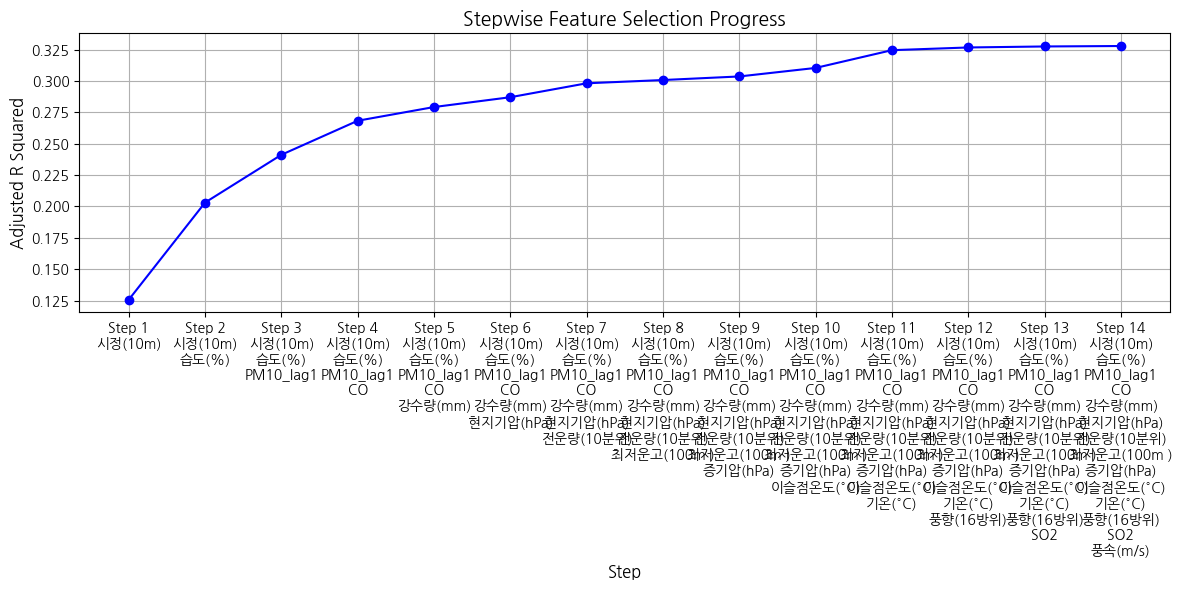

In [123]:
result = stepwise_feature_selection(X, df_21['PM10_1'])   # 한 시간 후 미세먼지 예측

In [124]:
result

['시정(10m)',
 '습도(%)',
 'PM10_lag1',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '최저운고(100m )',
 '증기압(hPa)',
 '이슬점온도(°C)',
 '기온(°C)',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)']

In [125]:
selected_features = result

In [127]:
selected_features

['시정(10m)',
 '습도(%)',
 'PM10_lag1',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '최저운고(100m )',
 '증기압(hPa)',
 '이슬점온도(°C)',
 '기온(°C)',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)']

In [ ]:
# selected_features.remove('5cm 지중온도(°C)')
# selected_features.remove('30cm 지중온도(°C)')
# selected_features.remove('이슬점온도(°C)')
# selected_features.remove('증기압(hPa)')

In [128]:
selected_features

['시정(10m)',
 '습도(%)',
 'PM10_lag1',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '최저운고(100m )',
 '증기압(hPa)',
 '이슬점온도(°C)',
 '기온(°C)',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)']

In [137]:
selected_features.remove('이슬점온도(°C)')

In [138]:
vif_result = vif(df_21, selected_features)
vif_result

,변수,VIF
1,시정(10m),1.758935
2,습도(%),3.276366
3,PM10_lag1,1.160427
4,CO,1.925710
5,강수량(mm),1.110588
6,현지기압(hPa),2.573118
7,전운량(10분위),1.875921
8,최저운고(100m ),1.877161
9,증기압(hPa),10.012610
10,기온(°C),8.090619


In [139]:
vif_result['변수'].to_list()

['시정(10m)',
 '습도(%)',
 'PM10_lag1',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '최저운고(100m )',
 '증기압(hPa)',
 '기온(°C)',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)']

In [140]:
temp_list = vif_result['변수'].to_list().copy()

In [141]:
temp_list.append('PM10_1')

In [142]:
df_21_corr = df_21[temp_list].corr()
df_21_corr

,시정(10m),습도(%),PM10_lag1,CO,강수량(mm),현지기압(hPa),전운량(10분위),최저운고(100m ),증기압(hPa),기온(°C),풍향(16방위),SO2,풍속(m/s),PM10_1
시정(10m),1.000000,-0.501971,-0.108528,-0.320544,-0.255393,0.138923,-0.240314,0.211467,-0.036314,0.071332,0.025305,-0.099209,0.106941,-0.354624
습도(%),-0.501971,1.000000,-0.139319,0.064612,0.174926,-0.360204,0.362515,-0.353423,0.451548,0.145767,-0.200527,-0.162225,-0.285478,-0.062749
PM10_lag1,-0.108528,-0.139319,1.000000,0.152218,-0.017551,0.011292,-0.096945,0.107966,-0.228518,-0.148163,0.100724,0.148667,0.090889,0.290011
CO,-0.320544,0.064612,0.152218,1.000000,-0.053421,0.340880,-0.049243,0.138895,-0.392311,-0.394170,-0.089282,0.340994,-0.289722,0.317638
강수량(mm),-0.255393,0.174926,-0.017551,-0.053421,1.000000,-0.117851,0.144385,-0.120700,0.090525,0.033725,-0.028189,-0.043431,0.067218,-0.053542
현지기압(hPa),0.138923,-0.360204,0.011292,0.340880,-0.117851,1.000000,-0.357664,0.379990,-0.711095,-0.678527,0.043627,-0.021522,-0.045096,0.022643
전운량(10분위),-0.240314,0.362515,-0.096945,-0.049243,0.144385,-0.357664,1.000000,-0.635352,0.356042,0.306234,-0.177396,0.018245,-0.028058,-0.099979
최저운고(100m ),0.211467,-0.353423,0.107966,0.138895,-0.120700,0.379990,-0.635352,1.000000,-0.335263,-0.250684,0.057623,0.029088,-0.097385,0.120052
증기압(hPa),-0.036314,0.451548,-0.228518,-0.392311,0.090525,-0.711095,0.356042,-0.335263,1.000000,0.881349,-0.189199,-0.064680,-0.148993,-0.204969
기온(°C),0.071332,0.145767,-0.148163,-0.394170,0.033725,-0.678527,0.306234,-0.250684,0.881349,1.000000,-0.182226,0.044873,-0.071882,-0.128247


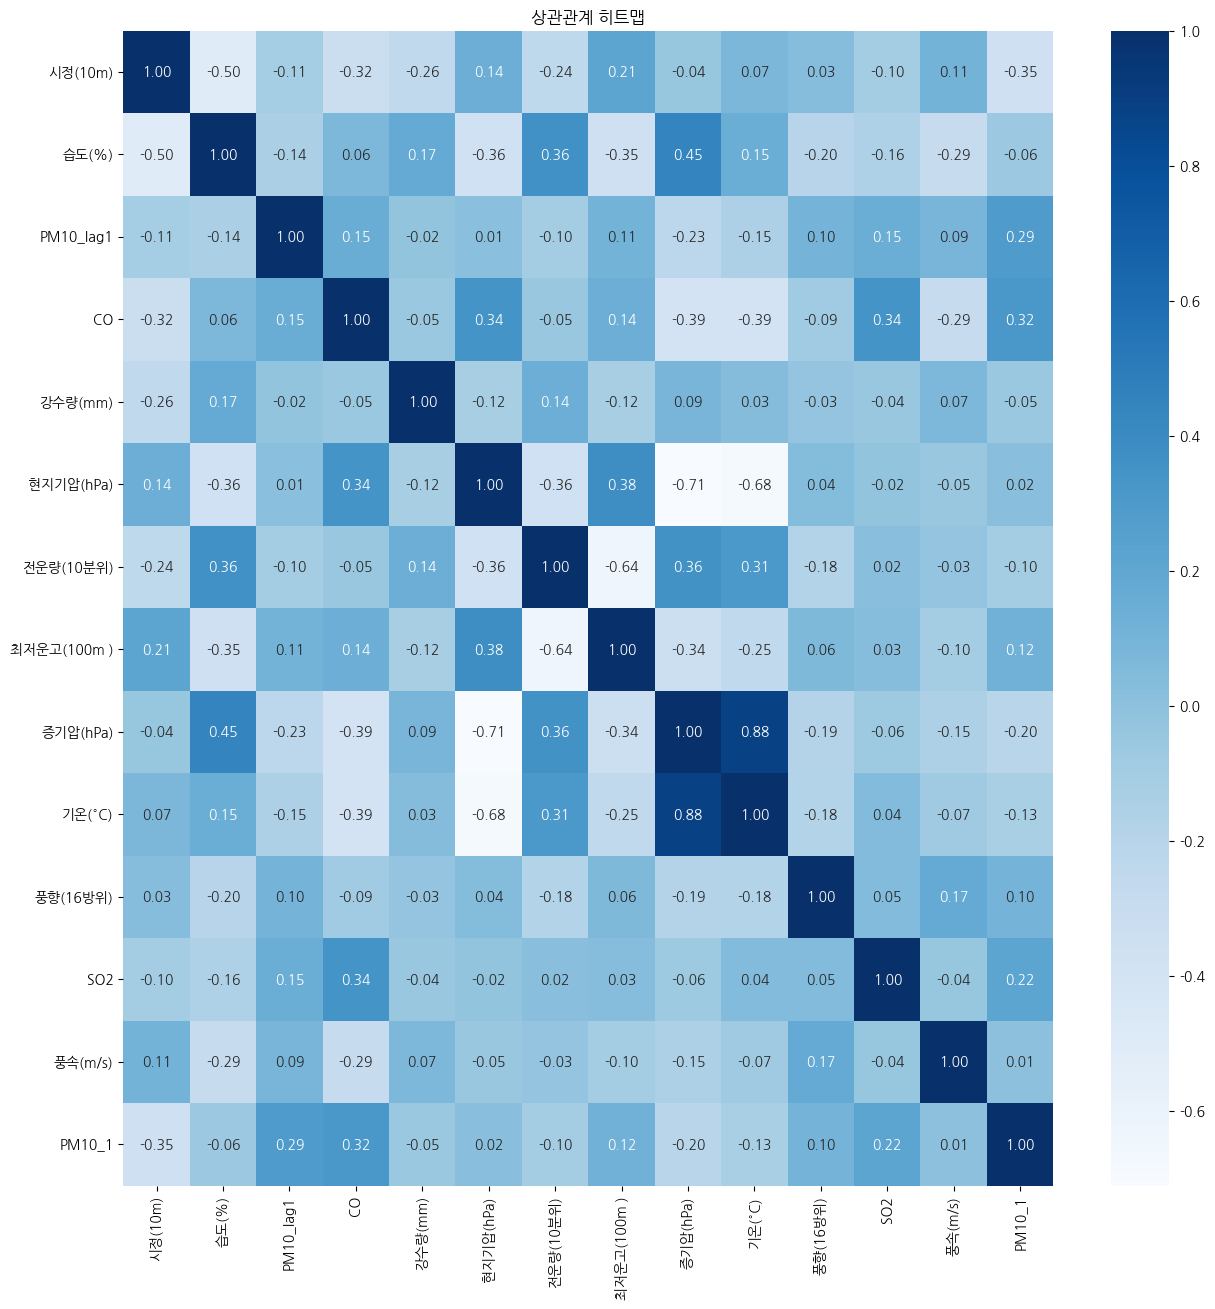

In [143]:
plt.figure(figsize=(15, 15))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [144]:
selected_features_final = vif_result['변수'].to_list()
selected_features_final

['시정(10m)',
 '습도(%)',
 'PM10_lag1',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '최저운고(100m )',
 '증기압(hPa)',
 '기온(°C)',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)']

# [4] 모델 훈련 및 테스트

## 4-1. 전체 데이터로 돌려보기

#### X, y 설정

In [ ]:
df_21.columns

In [ ]:
X_train = df_21[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                  '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                  '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                  '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                  '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values
X_test = df_22[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                 '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                 '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                 '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                 '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values

y_train = df_21['PM10_1']
y_test = df_22['PM10_1']

In [ ]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [ ]:
y_train

### LinearRegression

In [ ]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

In [ ]:
y_pred = regressor.predict(X_test_sc)

In [ ]:
y_pred

In [ ]:
y_test

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

In [ ]:
r2_score(y_test, y_pred)

### 랜덤포레스트

In [ ]:
regressor = RFR(random_state=42)
regressor.fit(X_train, y_train)

In [ ]:
y_pred = regressor.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

In [ ]:
r2_score(y_test, y_pred)

### XGBRegressor

In [ ]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

In [ ]:
grid_search.best_params_

In [ ]:
xgb_model = grid_search.best_estimator_

In [ ]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

In [ ]:
r2_score(y_test, y_pred)

## 4-2. 일부 변수만 선택해서 모델 훈련

#### X, y 설정

In [145]:
selected_features_final

['시정(10m)',
 '습도(%)',
 'PM10_lag1',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '최저운고(100m )',
 '증기압(hPa)',
 '기온(°C)',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)']

In [146]:
X_train = df_21[selected_features_final].values
X_test = df_22[selected_features_final].values

In [147]:
X_train

array([[2.0e+03, 3.9e+01, 2.4e+01, ..., 3.2e+02, 3.0e-03, 2.3e+00],
       [2.0e+03, 4.2e+01, 2.5e+01, ..., 2.7e+02, 3.0e-03, 2.7e+00],
       [2.0e+03, 4.5e+01, 2.7e+01, ..., 2.7e+02, 3.0e-03, 1.9e+00],
       ...,
       [2.0e+03, 3.5e+01, 2.4e+01, ..., 3.2e+02, 3.0e-03, 4.1e+00],
       [2.0e+03, 3.6e+01, 3.1e+01, ..., 3.2e+02, 3.0e-03, 4.8e+00],
       [2.0e+03, 3.7e+01, 2.8e+01, ..., 3.2e+02, 3.0e-03, 3.0e+00]])

In [148]:
X_test

array([[2.0e+03, 5.5e+01, 2.0e+01, ..., 5.0e+01, 5.0e-03, 2.3e+00],
       [2.0e+03, 5.7e+01, 2.3e+01, ..., 5.0e+01, 4.0e-03, 2.1e+00],
       [2.0e+03, 5.7e+01, 2.0e+01, ..., 5.0e+01, 4.0e-03, 1.9e+00],
       ...,
       [2.0e+03, 4.8e+01, 3.4e+01, ..., 3.4e+02, 2.0e-03, 2.7e+00],
       [2.0e+03, 5.1e+01, 4.9e+01, ..., 3.2e+02, 2.0e-03, 3.5e+00],
       [2.0e+03, 5.8e+01, 5.1e+01, ..., 5.0e+01, 3.0e-03, 1.9e+00]])

In [149]:
y_train = df_21['PM10_1']
y_test = df_22['PM10_1']
y_train

,PM10_1
24,25.0
25,29.0
26,24.0
27,20.0
28,19.0
...,...
8753,25.0
8754,26.0
8755,27.0
8756,20.0


In [150]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### LinearRegression

In [79]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

LinearRegression()

In [80]:
y_pred = regressor.predict(X_test_sc)

In [81]:
y_pred

array([52.77683169, 28.62170549, 28.17367106, ..., 38.35564851,
       35.34842574, 20.82210262])

In [82]:
y_test

,PM10_1
24,38.0
25,34.0
26,35.0
27,33.0
28,33.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [83]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

16.81300843673272


In [84]:
r2_score(y_test, y_pred)

0.4918158882726663

### 랜덤포레스트

In [96]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

rf_model = RFR(random_state=42)

grid_search = GridSearchCV(estimator=rf_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

In [97]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='neg_mean_squared_error', verbose=1)

In [98]:
best_params = grid_search.best_params_

In [99]:
rf_model = RFR(**best_params, random_state=42)

In [100]:
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=200, random_state=42)

In [101]:
y_pred = rf_model.predict(X_test)

In [102]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

16.055646094761116


In [103]:
r2_score(y_test, y_pred)

0.5365682392219291

### XGBRegressor

In [151]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='neg_mean_squared_error', verbose=1)

In [152]:
grid_search.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.1,
 'max_depth': 4,
 'n_estimators': 50,
 'subsample': 1.0}

In [153]:
xgb_model = grid_search.best_estimator_

In [154]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

13.786284082645714


In [155]:
r2_score(y_test, y_pred)

0.6583159801909475

In [156]:
y_pred

array([39.06289 , 37.026104, 37.095932, ..., 31.524836, 30.278471,
       20.31998 ], dtype=float32)

In [157]:
y_test.values

array([38., 34., 35., ..., 10., 11., 11.])